# Named Entity Recognition, step by step

This notebook opens up a modern **Named Entity Recognition (NER)** system and
follows a single sentence from a clinical case report all the way through it:

```
sentence (MultiCaRe case report)
  │  ① spaCy / scispaCy: sentence splitting + word tokens        (rules, visible)
  │  ② static word vectors (spaCy)                                (one vector per word type)
  ▼
  ③ WordPiece tokenizer (Hugging Face)                            (sub-word pieces + ids)
  ▼
  ④ layer 0: BERT's own embedding table (token + position)        (static, context-free)
  ▼
  ⑤ 6 Transformer layers (self-attention)                         (vectors become contextual)
  ▼
  ⑥ classifier head: Linear(768 → 84) + softmax                   (one label per sub-word)
  ▼
  ⑦ sub-word labels → word labels → entity spans → spaCy Doc → displacy
```

Then it asks **what fine-tuning actually changed** (⑧), by comparing the
fine-tuned NER model with the general-purpose model it started from, and
ends with the NER that was inside the spaCy pipeline all along, built on a
**completely different architecture** (⑨).

**Models**

| Role | Model | Notes |
|---|---|---|
| Tokenization, sentences, POS, untyped NER | `en_core_sci_sm` (scispaCy 0.5.4) | trained on biomedical text; CNN + transition-based NER |
| Static word vectors | `en_core_web_md` (spaCy) | 20k general-English vectors, 300 dims |
| Fine-tuned NER | [`d4data/biomedical-ner-all`](https://huggingface.co/d4data/biomedical-ner-all) | DistilBERT fine-tuned on MACCROBAT (case reports) |
| Starting point of the fine-tuning | [`distilbert-base-uncased`](https://huggingface.co/distilbert-base-uncased) | general English, no NER head |

**Data**: a 50-article sample of [MultiCaRe](https://doi.org/10.5281/zenodo.10079369)
case reports (`sample/`, same corpus as the `to-kg` project) for the
walkthrough, and [MACCROBAT2018](https://doi.org/10.6084/m9.figshare.9764942.v2)
(CC BY 4.0) for the comparison in step ⑧.

Cells marked **🧩 Challenge** are for you to solve.

## 0. Setup

Everything runs on CPU. On first local run the models (~0.5 GB) and
MACCROBAT (~1 MB) are downloaded; on Binder they are already inside the image.

In [1]:
import os
import warnings

warnings.filterwarnings("ignore")  # quiet spaCy/transformers deprecation chatter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import spacy
from spacy import displacy
from spacy.util import filter_spans
import transformers
from transformers import AutoTokenizer, AutoModel, AutoModelForTokenClassification, pipeline

from IPython.display import HTML, display

import ner_helpers

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
torch.manual_seed(0)
pd.set_option("display.max_colwidth", 80)

print("spaCy", spacy.__version__, "| transformers", transformers.__version__, "| torch", torch.__version__)

spaCy 3.7.5 | transformers 5.22.1 | torch 2.15.0+cpu


In [2]:
# ---- configuration -------------------------------------------------------
SPACY_MODEL = "en_core_sci_sm"     # pipeline: tokenizer, sentences, POS, NER
STATIC_VECTORS = "en_core_web_md"  # static word vectors (on a machine with
                                   # > 3 GB RAM, try scispaCy's "en_core_sci_md")
FT_MODEL    = "d4data/biomedical-ner-all"   # fine-tuned for NER
BASE_MODEL  = "distilbert-base-uncased"     # what it was fine-tuned from

CASES_CSV = "sample/cases.csv"

# The walkthrough sentence (from case PMC5137649_01 of the sample).
CASE_ID = "PMC5137649_01"
SENTENCE_STARTS_WITH = "A 44-year-old woman presented"

# Entity types used in step ⑧ (a readable subset of MACCROBAT's 40+ types).
COMPARE_LABELS = ["Sign_symptom", "Disease_disorder", "Diagnostic_procedure",
                  "Therapeutic_procedure", "Medication", "Biological_structure"]
WORDS_PER_LABEL = 150   # balanced sample size per entity type in step ⑧

COLORS = {"Sign_symptom": "#f4a582", "Disease_disorder": "#d6604d",
          "Diagnostic_procedure": "#92c5de", "Therapeutic_procedure": "#4393c3",
          "Medication": "#b8e186", "Biological_structure": "#fee08b",
          "ENTITY": "#c2a5cf"}

## 1. Raw text and the spaCy pipeline

A spaCy `Language` object (`nlp`) is a **pipeline**: the text is first cut
into tokens by a rule-based **tokenizer**, then each component in
`nlp.pipe_names` adds annotations to the same `Doc` object.

In [3]:
cases = pd.read_csv(CASES_CSV)
print(cases.shape)
cases.head(3)

(56, 5)


,article_id,age,case_id,case_text,gender
0,PMC5137649,44.0,PMC5137649_01,A 44-year-old woman presented with a 3-day history of right flank and lower ...,Female
1,PMC9387390,57.0,PMC9387390_01,A 57-year-old man with no significant past medical or surgical history initi...,Male
2,PMC3437073,55.0,PMC3437073_01,A 55-year-old male presented with a gradually increasing mass on the left la...,Male


In [4]:
case_text = cases.set_index("case_id").loc[CASE_ID, "case_text"]
print(case_text[:700], "...")

A 44-year-old woman presented with a 3-day history of right flank and lower quadrant abdominal pain associated with nausea and constipation. Her past medical, family and medication history were otherwise non-contributory and her physical examination was unremarkable. She underwent contrast enhanced computed tomography, demonstrating a 6cm cystic lesion between the stomach and body/tail of the pancreas (Fig 1). She subsequently underwent EUS-FNA, which revealed normal pancreatic echotexture and a cyst measuring 6cm x 9cm that was free of internal septations or associated masses (Fig 2) but compressed the stomach. FNA of the cyst demonstrated no evidence of malignancy but did show the presence ...


In [5]:
nlp = spacy.load(SPACY_MODEL)
print("tokenizer:", type(nlp.tokenizer).__name__)
print("pipeline :", nlp.pipe_names)

tokenizer: Tokenizer
pipeline : ['tok2vec', 'tagger', 'attribute_ruler', 'lemmatizer', 'parser', 'ner']


| Component | What it adds |
|---|---|
| *tokenizer* (not in `pipe_names`) | splits text into `Token`s with rules: whitespace, then prefixes/suffixes/infixes and exceptions (`"Dr."` stays one token) |
| `tok2vec` | a small CNN that computes a vector per token, shared by the components below |
| `tagger` | part-of-speech tags (`token.tag_`) |
| `attribute_ruler`, `lemmatizer` | coarse POS (`token.pos_`) and lemmas (`token.lemma_`) |
| `parser` | dependency tree — and, as a by-product, **sentence boundaries** (`doc.sents`) |
| `ner` | entity spans — this model only says *"this is an entity"* (label `ENTITY`), no types; we come back to it in step ⑨ |

In [6]:
doc = nlp(case_text)
sentences = [s.text for s in doc.sents]
print(len(sentences), "sentences in this case\n")
for i, s in enumerate(sentences[:5]):
    print(i, "|", s)

18 sentences in this case

0 | A 44-year-old woman presented with a 3-day history of right flank and lower quadrant abdominal pain associated with nausea and constipation.
1 | Her past medical, family and medication history were otherwise non-contributory and her physical examination was unremarkable.
2 | She underwent contrast enhanced computed tomography, demonstrating a 6cm cystic lesion between the stomach and body/tail of the pancreas (Fig 1).
3 | She subsequently underwent EUS-FNA, which revealed normal pancreatic echotexture and a cyst measuring 6cm x 9cm that was free of internal septations or associated masses (Fig 2) but compressed the stomach.
4 | FNA of the cyst demonstrated no evidence of malignancy but did show the presence of extracellular mucin as well as a carcinoembryonic antigen (CEA) level of 12,476.5ng/ml and a carbohydrate antigen (CA) 19-9 level of 6iu/ml, suggesting the diagnosis of a mucinous pancreatic cystic neoplasm.


In [7]:
sentence = next(s for s in sentences if s.startswith(SENTENCE_STARTS_WITH))
sdoc = nlp(sentence)
print(sentence, "\n")

pd.DataFrame([{
    "i": t.i, "text": t.text, "char_offset": t.idx, "lemma": t.lemma_, "pos": t.pos_,
    "shape": t.shape_, "is_stop": t.is_stop,
} for t in sdoc])

A 44-year-old woman presented with a 3-day history of right flank and lower quadrant abdominal pain associated with nausea and constipation. 



,i,text,char_offset,lemma,pos,shape,is_stop
0,0,A,0,a,DET,X,True
1,1,44-year-old,2,44-year-old,ADJ,dd-xxxx-xxx,False
2,2,woman,14,woman,NOUN,xxxx,False
3,3,presented,20,present,VERB,xxxx,False
4,4,with,30,with,ADP,xxxx,True
5,5,a,35,a,DET,x,True
6,6,3-day,37,3-day,ADJ,d-xxx,False
7,7,history,43,history,NOUN,xxxx,False
8,8,of,51,of,ADP,xx,True
9,9,right,54,right,ADJ,xxxx,False


scispaCy's tokenizer keeps `44-year-old` as a single token (its rules were
tuned for biomedical text) — watch what WordPiece does with it in step 3.
The **character offsets** (`char_offset`) are the common currency we will use
later to line up spaCy tokens, WordPiece tokens and gold annotations.

## 2. Static word vectors

Our biomedical pipeline is the *small* scispaCy model, which has **no word
vectors** (`nlp.vocab.vectors` is empty). We load them from spaCy's
`en_core_web_md`, keeping only its vector table: **static** vectors trained
on web text, one 300-dimensional vector per word *type*, looked up by the
token's text no matter the context.

In [8]:
print("vectors in", SPACY_MODEL, ":", nlp.vocab.vectors.shape)

vec_nlp = spacy.load(STATIC_VECTORS, exclude=["tok2vec", "tagger", "parser", "senter",
                                              "attribute_ruler", "lemmatizer", "ner"])
vectors = vec_nlp.vocab.vectors
print("vector table of", STATIC_VECTORS, ":", vectors.shape, "(rows × dims)")
print("words (keys) mapped onto it:", vectors.n_keys)

vectors in en_core_sci_sm : (0, 0)
vector table of en_core_web_md : (20000, 300) (rows × dims)
words (keys) mapped onto it: 514157


There are many more keys than rows: the table was **pruned** — rare words
were mapped onto the row of their nearest kept neighbor to save memory, so
some different words literally share one vector.

Similarities between a few clinical words (vectors from *general* web text —
keep that in mind):

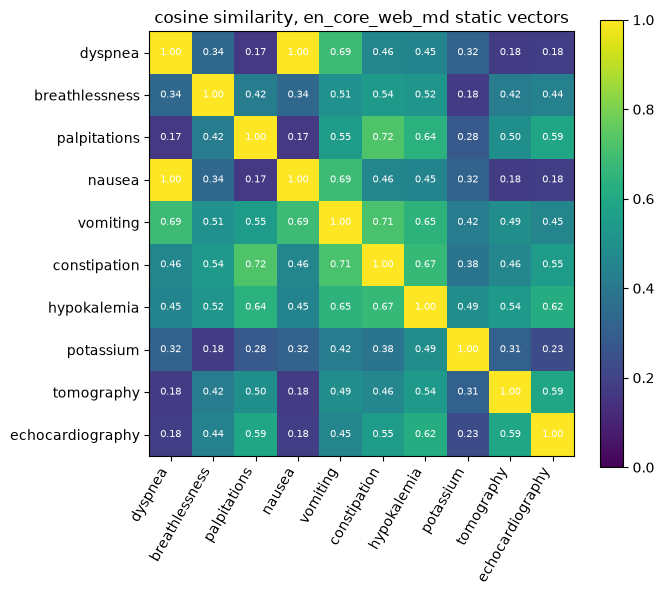

In [9]:
def cosine(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

words = ["dyspnea", "breathlessness", "palpitations", "nausea", "vomiting",
         "constipation", "hypokalemia", "potassium", "tomography", "echocardiography"]
sim = pd.DataFrame([[cosine(vec_nlp.vocab[a].vector, vec_nlp.vocab[b].vector) for b in words] for a in words],
                   index=words, columns=words)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(sim, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(words)), words, rotation=60, ha="right"); ax.set_yticks(range(len(words)), words)
for i in range(len(words)):
    for j in range(len(words)):
        ax.text(j, i, f"{sim.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
fig.colorbar(im); ax.set_title(f"cosine similarity, {STATIC_VECTORS} static vectors"); plt.tight_layout()

Did you spot a similarity of exactly **1.00** between two different words?
That is the pruning at work — both keys point to the same row:

In [10]:
for w in ["dyspnea", "nausea", "vomiting"]:
    print(f"{w:10s} → row {vectors.find(key=w)}")

dyspnea    → row 18050
nausea     → row 18050
vomiting   → row 17911


**The limitation of static vectors:** a word gets the *same* vector in every
sentence. Two real sentences from our sample use *culture* in very different
senses:

In [11]:
def find_sentence(substring):
    # first sentence of the sample containing `substring`
    for text in cases.case_text:
        if substring in text:
            for s in nlp(text).sents:
                if substring in s.text:
                    return s.text.strip()
    raise ValueError(substring)

CONTEXT_PAIRS = {
    # word: (clinical sense A, clinical sense A again, a different sense B)
    "culture": (find_sentence("The biliary culture was positive"),
                find_sentence("Upon culture and sensitivity results"),
                find_sentence("characterized the Theranos culture")),
    "cold":    (find_sentence("cold agglutinin titer"),
                find_sentence("antegrade cold blood cardioplegia"),
                find_sentence("tenacious, cold, and obsessed")),
}
for w, (a1, a2, b) in CONTEXT_PAIRS.items():
    print(f"[{w}]\n  A1: {a1}\n  A2: {a2[:160]}\n  B : {b}\n")

v_a = [t.vector for t in vec_nlp(CONTEXT_PAIRS["culture"][0]) if t.lower_ == "culture"][0]
v_b = [t.vector for t in vec_nlp(CONTEXT_PAIRS["culture"][2]) if t.lower_ == "culture"][0]
print("static cosine( culture in A1 , culture in B ) =", round(cosine(v_a, v_b), 4))

[culture]
  A1: The biliary culture was positive for ESBL-producing Klebsiella pneumoniae.
  A2: Upon culture and sensitivity results, the antibiotics were changed to ceftaroline, gentamicin, and linezolid for presumed IE according to Duke's criteria in the
  B : The secrecy and results-driven demands that characterized the Theranos culture were easily dismissed and excused because of how closely they mirrored the norm.

[cold]
  A1: Autoimmune hemolytic anemia was also confirmed, with laboratory data revealing a cold agglutinin titer Positive dilution 1/128 at 4 C, hemoglobin 6.2 g/dl, hematocrit 18.1% and monospecific direct antiglobulin strongly positive for C3d and negative for IgG, leading to the diagnosis of cold agglutinin syndrome.
  A2: Myocardial protection was achieved with antegrade cold blood cardioplegia at a core temperature of 28 C.
Right ventriculotomy was carried out, and VSD was close
  B : She captivated Silicon Valley because she was familiar:tenacious, cold, and o

> **Aside — what spaCy's own components see.** The `tok2vec` component does
> *not* look up one vector per word. It hashes several features of each
> token (`NORM`, `PREFIX`, `SUFFIX`, `SHAPE`, ...) into small embedding tables
> (plus static vectors, in models that have them) and runs a CNN over a
> window of neighbors:

In [12]:
nlp.config["components"]["tok2vec"]["model"]["embed"]

{'@architectures': 'spacy.MultiHashEmbed.v2',
 'width': 96,
 'attrs': ['NORM', 'PREFIX', 'SUFFIX', 'SHAPE', 'SPACY', 'IS_SPACE'],
 'rows': [5000, 1000, 2500, 2500, 50, 50],
 'include_static_vectors': 'False'}

That is powerful but hard to inspect, so for the rest of the walkthrough we
switch to a Transformer, where every intermediate tensor can be pulled out.

## 3. WordPiece tokenization

BERT-family models do not use spaCy's tokens. Their tokenizer first splits
on whitespace and punctuation, then breaks each word into **sub-word pieces**
from a fixed vocabulary of 30,522 entries (WordPiece). Pieces that continue a
word start with `##`. Special tokens `[CLS]` and `[SEP]` are added at the ends.

In [13]:
tokenizer = AutoTokenizer.from_pretrained(FT_MODEL)
print(type(tokenizer).__name__, "| vocabulary size:", tokenizer.vocab_size)

enc = tokenizer(sentence, return_offsets_mapping=True, return_tensors="pt")
pieces = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
word_ids = enc.word_ids()

wp = pd.DataFrame({
    "position": range(len(pieces)),
    "piece": pieces,
    "input_id": enc["input_ids"][0].tolist(),
    "word_id": pd.array(word_ids, dtype="Int64"),
    "chars": [tuple(o) for o in enc["offset_mapping"][0].tolist()],
})
wp

DistilBertTokenizer | vocabulary size: 30522


,position,piece,input_id,word_id,chars
0,0,[CLS],101,<NA>,"(0, 0)"
1,1,a,1037,0,"(0, 1)"
2,2,44,4008,1,"(2, 4)"
3,3,-,1011,2,"(4, 5)"
4,4,year,2095,3,"(5, 9)"
5,5,-,1011,4,"(9, 10)"
6,6,old,2214,5,"(10, 13)"
7,7,woman,2450,6,"(14, 19)"
8,8,presented,3591,7,"(20, 29)"
9,9,with,2007,8,"(30, 34)"


In [14]:
print("spaCy tokens    :", len(sdoc))
print("WordPiece pieces:", len(pieces), "(including [CLS] and [SEP])\n")
for w in ["constipation", "hypokalemia", "dyspnea", "echocardiography", "44-year-old"]:
    print(f"{w:18s} → {tokenizer.tokenize(w)}")

spaCy tokens    : 22
WordPiece pieces: 33 (including [CLS] and [SEP])

constipation       → ['con', '##sti', '##pati', '##on']
hypokalemia        → ['h', '##yp', '##oka', '##lem', '##ia']
dyspnea            → ['d', '##ys', '##p', '##nea']
echocardiography   → ['echo', '##card', '##iography']
44-year-old        → ['44', '-', 'year', '-', 'old']


The tokenizer is **uncased**: everything was lower-cased first. Frequent
words are single pieces; rarer clinical words are split, sometimes into
pieces that carry little meaning on their own (`h`, `##yp`, `##oka`, ...).
The model has to rebuild their meaning from context.

## 4. Layer 0 — BERT's own static embeddings

Which "static embedding library" does BERT use? **None from outside**: the
model carries its own learned embedding table, one 768-dimensional row per
vocabulary entry, plus a table of **position** embeddings. This first step
is still context-free.

In [15]:
ft_model = AutoModelForTokenClassification.from_pretrained(FT_MODEL, attn_implementation="eager").eval()
print(ft_model)

DistilBertForTokenClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(p=0

In [16]:
emb = ft_model.distilbert.embeddings
print("word_embeddings    :", tuple(emb.word_embeddings.weight.shape))
print("position_embeddings:", tuple(emb.position_embeddings.weight.shape))

input_ids = enc["input_ids"]
positions = torch.arange(input_ids.shape[1]).unsqueeze(0)

with torch.no_grad():
    token_vecs    = emb.word_embeddings(input_ids)        # look up one row per piece
    position_vecs = emb.position_embeddings(positions)    # one row per position 0, 1, 2, ...
    layer0_manual = emb.LayerNorm(token_vecs + position_vecs)

    out = ft_model(input_ids=input_ids, attention_mask=enc["attention_mask"],
                   output_hidden_states=True, output_attentions=True)

print("\nhidden_states: a tuple of", len(out.hidden_states), "tensors (layer 0 + 6 Transformer layers), each", tuple(out.hidden_states[0].shape))
print("our manual layer 0 equals the model's layer 0:", torch.allclose(layer0_manual, out.hidden_states[0], atol=1e-5))

word_embeddings    : (30522, 768)
position_embeddings: (512, 768)

hidden_states: a tuple of 7 tensors (layer 0 + 6 Transformer layers), each (1, 33, 768)
our manual layer 0 equals the model's layer 0: True


## 5. Six Transformer layers: from static to contextual

Each layer mixes information between positions with **self-attention**
(here 12 heads per layer), then applies a feed-forward network. Let's look
at where each piece "looks" in the last layer (average of the 12 heads).
For a head-by-head, interactive view see the bertviz notebook in
`machine-learning/neural-network/attention/bertviz/`.

attentions: 6 layers, each (1, 12, 33, 33) (batch, heads, from, to)


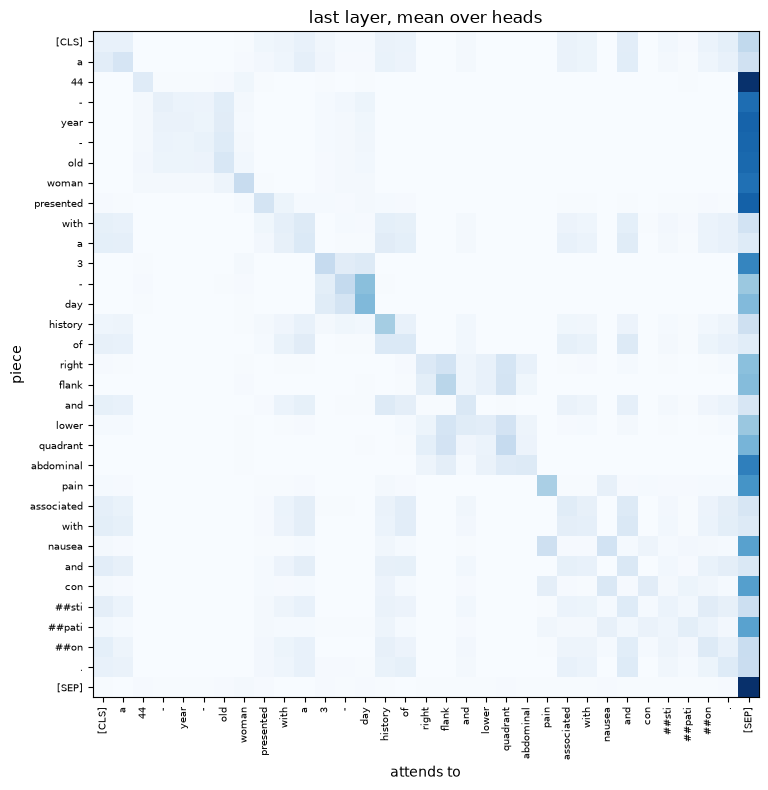

In [17]:
print("attentions:", len(out.attentions), "layers, each", tuple(out.attentions[0].shape), "(batch, heads, from, to)")

att = out.attentions[-1][0].mean(0).numpy()
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(att, cmap="Blues")
ax.set_xticks(range(len(pieces)), pieces, rotation=90, fontsize=7)
ax.set_yticks(range(len(pieces)), pieces, fontsize=7)
ax.set_xlabel("attends to"); ax.set_ylabel("piece"); ax.set_title("last layer, mean over heads")
plt.tight_layout()

Now the key effect. We take the vector of one word in two sentences and
measure their cosine similarity **at every layer**. At layer 0 only the
position differs; after that, attention lets the context reshape the vector.

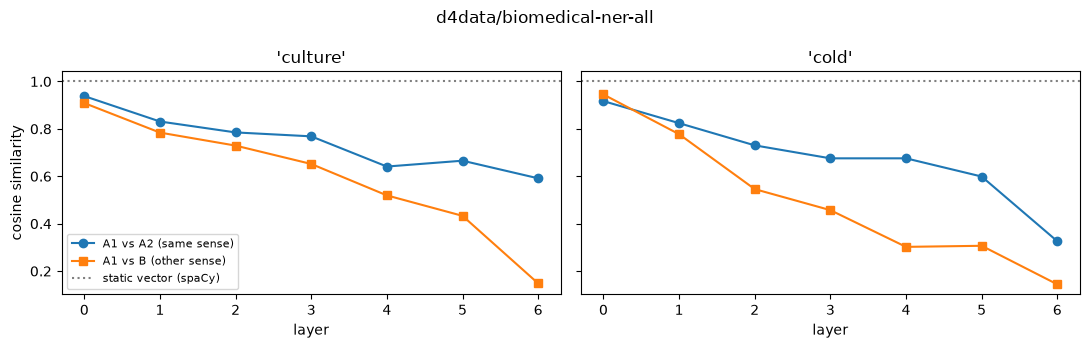

In [18]:
def word_vectors_by_layer(model, tokenizer, text, word):
    # vectors (n_layers+1, 768) of the first piece of the first occurrence of `word`
    enc = tokenizer(text, return_offsets_mapping=True, return_tensors="pt", truncation=True)
    start = text.lower().index(word.lower())
    idx = next(i for i, (s, e) in enumerate(enc["offset_mapping"][0].tolist()) if s == start and e > s)
    with torch.no_grad():
        hs = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"],
                   output_hidden_states=True).hidden_states
    return torch.stack([h[0, idx] for h in hs]).numpy()

def plot_context_curves(model, title):
    fig, axes = plt.subplots(1, len(CONTEXT_PAIRS), figsize=(11, 3.5), sharey=True)
    for ax, (w, (a1, a2, b)) in zip(axes, CONTEXT_PAIRS.items()):
        va1, va2, vb = (word_vectors_by_layer(model, tokenizer, t, w) for t in (a1, a2, b))
        ax.plot([cosine(x, y) for x, y in zip(va1, va2)], "o-", label="A1 vs A2 (same sense)")
        ax.plot([cosine(x, y) for x, y in zip(va1, vb)], "s-", label="A1 vs B (other sense)")
        ax.axhline(1.0, color="gray", ls=":", label="static vector (spaCy)")
        ax.set_title(f"'{w}'"); ax.set_xlabel("layer"); ax.set_xticks(range(len(va1)))
    axes[0].set_ylabel("cosine similarity"); axes[0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout()

plot_context_curves(ft_model, FT_MODEL)

## 6. The classifier: its input and its output

After the last layer, a **single linear layer** turns each 768-dimensional
contextual vector into 84 scores (*logits*), one per label. That is the whole
"NER part" of the model — everything before it is the encoder.

In [19]:
clf = ft_model.classifier
print(clf)
print("weight", tuple(clf.weight.shape), "| bias", tuple(clf.bias.shape))

id2label = ft_model.config.id2label
print("\nlabels:", len(id2label), "→", list(id2label.values())[:12], "...")

Linear(in_features=768, out_features=84, bias=True)
weight (84, 768) | bias (84,)

labels: 84 → ['O', 'B-Activity', 'B-Administration', 'B-Age', 'B-Area', 'B-Biological_attribute', 'B-Biological_structure', 'B-Clinical_event', 'B-Color', 'B-Coreference', 'B-Date', 'B-Detailed_description'] ...


In [20]:
h_last = out.hidden_states[-1][0]                 # classifier INPUT : (n_pieces, 768)
logits_manual = h_last @ clf.weight.T + clf.bias  # classifier OUTPUT: (n_pieces, 84)

print("input :", tuple(h_last.shape))
print("output:", tuple(logits_manual.shape))
print("manual logits equal the model's logits:", torch.allclose(logits_manual, out.logits[0], atol=1e-4))

input : (33, 768)
output: (33, 84)
manual logits equal the model's logits: True


In [21]:
probs = torch.softmax(out.logits[0], dim=-1)
top = probs.topk(3, dim=-1)

rows = []
for i, piece in enumerate(pieces):
    row = {"piece": piece, "input (first 4 of 768 dims)": np.round(h_last[i, :4].numpy(), 2)}
    for k in range(3):
        row[f"top{k+1}"] = f"{id2label[int(top.indices[i, k])]} ({top.values[i, k]:.2f})"
    rows.append(row)
pd.DataFrame(rows)

,piece,input (first 4 of 768 dims),top1,top2,top3
0,[CLS],"[-1.08, -0.72, -1.25, 0.09]",O (1.00),B-Lab_value (0.00),B-Other_entity (0.00)
1,a,"[-1.0, -0.66, -1.19, -0.02]",O (1.00),B-Lab_value (0.00),I-Other_entity (0.00)
2,44,"[0.83, 1.7, 0.16, -0.31]",B-Age (1.00),I-Age (0.00),B-Personal_[back](Biological_structure (0.00)
3,-,"[-0.12, -0.2, 0.37, -0.58]",I-Age (1.00),B-Personal_[back](Biological_structure (0.00),I-Duration (0.00)
4,year,"[-0.15, -0.12, 0.55, -0.47]",I-Age (1.00),B-Personal_[back](Biological_structure (0.00),I-Duration (0.00)
5,-,"[-0.24, -0.11, 0.31, -0.57]",I-Age (1.00),B-Personal_[back](Biological_structure (0.00),I-Personal_background (0.00)
6,old,"[-0.11, -0.15, 0.29, -0.6]",I-Age (1.00),B-Personal_[back](Biological_structure (0.00),B-Sex (0.00)
7,woman,"[0.74, -0.44, -0.1, -0.67]",B-Sex (1.00),B-Age (0.00),I-Subject (0.00)
8,presented,"[-1.16, 0.93, -0.07, 0.23]",B-Clinical_event (1.00),B-Activity (0.00),B-Outcome (0.00)
9,with,"[-0.9, -0.62, -1.23, -0.09]",O (1.00),B-Lab_value (0.00),I-Other_entity (0.00)


> 🔍 Look closely at the label list: a few labels are broken, e.g.
> `Non[biological](Detailed_description`. They are leftovers of malformed
> annotations in the training data — a reminder that models inherit the
> mess of their datasets.

In [22]:
[l for l in id2label.values() if "[" in l or "(" in l]

['B-Non[biological](Detailed_description',
 'B-Personal_[back](Biological_structure']

## 7. From sub-word labels to entities

The classifier labels **pieces**, but we want **spans of words**. The labels
use the **BIO** scheme: `B-X` begins an entity of type X, `I-X` continues
it, `O` is outside any entity. Look at what the raw piece labels look like:

In [23]:
pred = out.logits[0].argmax(-1).tolist()
pd.DataFrame({"piece": pieces, "word_id": pd.array(word_ids, dtype="Int64"),
              "label": [id2label[p] for p in pred]}).T

,0,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,32
piece,[CLS],a,44,-,year,-,old,woman,presented,with,...,associated,with,nausea,and,con,##sti,##pati,##on,.,[SEP]
word_id,<NA>,0,1,2,3,4,5,6,7,8,...,22,23,24,25,26,26,26,26,27,<NA>
label,O,O,B-Age,I-Age,I-Age,I-Age,I-Age,B-Sex,B-Clinical_event,O,...,O,O,B-Sign_symptom,O,B-Sign_symptom,O,B-Sign_symptom,O,O,O


Pieces of one word may disagree — find the four pieces of *constipation*
(`con ##sti ##pati ##on`) in the table above. A common fix is to keep only the label of each word's **first piece**,
then group consecutive words into spans:

In [24]:
def decode_entities(text, enc, pred_label_ids, id2label):
    # first-piece word labels → BIO spans: [(start_char, end_char, type), ...]
    word_ids = enc.word_ids()
    words = []
    for w in sorted({w for w in word_ids if w is not None}):
        first_piece = word_ids.index(w)
        start, end = enc.word_to_chars(w)
        words.append((start, end, id2label[pred_label_ids[first_piece]]))

    spans = []
    for start, end, label in words:
        if label == "O":
            continue
        tag, etype = label.split("-", 1)
        if tag == "I" and spans and spans[-1][2] == etype:
            spans[-1] = (spans[-1][0], end, etype)       # continue the current entity
        else:
            spans.append((start, end, etype))             # B-, or an I- with no matching B-
    return spans

entities = decode_entities(sentence, enc, pred, id2label)
pd.DataFrame([(sentence[s:e], t, s, e) for s, e, t in entities], columns=["text", "type", "start", "end"])

,text,type,start,end
0,44-year-old,Age,2,13
1,woman,Sex,14,19
2,presented,Clinical_event,20,29
3,3-day,Duration,37,42
4,right flank,Biological_structure,54,65
5,lower quadrant,Biological_structure,70,84
6,abdominal,Biological_structure,85,94
7,pain,Sign_symptom,95,99
8,nausea,Sign_symptom,116,122
9,constipation,Sign_symptom,127,139


Hugging Face's `pipeline` implements the same idea; with
`aggregation_strategy="first"` it should give the same spans:

In [25]:
ner_pipe = pipeline("token-classification", model=ft_model, tokenizer=tokenizer, aggregation_strategy="first")
pd.DataFrame(ner_pipe(sentence))[["word", "entity_group", "score", "start", "end"]]

,word,entity_group,score,start,end
0,44 - year - old,Age,0.998256,2,13
1,woman,Sex,0.999812,14,19
2,presented,Clinical_event,0.999343,20,29
3,3 - day,Duration,0.999750,37,42
4,right flank,Biological_structure,0.999917,54,65
5,lower quadrant,Biological_structure,0.998351,70,84
6,abdominal,Biological_structure,0.999958,85,94
7,pain,Sign_symptom,0.999968,95,99
8,nausea,Sign_symptom,0.999951,116,122
9,constipation,Sign_symptom,0.999791,127,139


Finally we go back to spaCy: the character offsets let us attach these
entities to a spaCy `Doc` (built with spaCy's own tokenizer) and render
them with `displacy`.

In [26]:
def show_entities(text, spans, title=None):
    d = nlp.make_doc(text)
    ents = [d.char_span(s, e, label=t, alignment_mode="expand") for s, e, t in spans]
    d.ents = filter_spans([x for x in ents if x is not None])
    if title:
        d.user_data["title"] = title
    display(HTML(displacy.render(d, style="ent", jupyter=False, options={"colors": COLORS})))

show_entities(sentence, entities, FT_MODEL)

In [27]:
# the same pipeline on the first sentences of the case
for s in sentences[1:4]:
    e = ner_pipe(s)
    show_entities(s, [(x["start"], x["end"], x["entity_group"]) for x in e])

### 🧩 Challenge 1 — tokenization and decoding

1. Find a sentence in `cases` where an entity is split into **5 or more**
   WordPiece pieces and the pieces receive **inconsistent** labels.
2. Write an alternative to `decode_entities` that labels each word by
   **majority vote** (or by the **average probability**) over its pieces.
   Compare with `pipeline(..., aggregation_strategy="average")` and `"max"`.
   Where do the strategies disagree?

In [28]:
# your code here

## 8. What did fine-tuning change?

`d4data/biomedical-ner-all` was created by taking `distilbert-base-uncased`
and training it (with a fresh classifier head) on **MACCROBAT**, a corpus of
200 case reports annotated with entity types. Same architecture, same
vocabulary — only the weights differ. So we can ask:

> *Do embeddings of words of the same entity type end up **closer to each
> other** — and to their "type" — after fine-tuning?*

⚠️ We measure this on MACCROBAT itself, i.e. on the model's **training
data**. That is deliberate: we want to *see* how fine-tuning reshaped the
space, not to estimate the model's accuracy on new text (which would require
held-out data).

In [29]:
base_model = AutoModel.from_pretrained(BASE_MODEL).eval()
base_tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

print("same vocabulary:", base_tokenizer.get_vocab() == tokenizer.get_vocab())
print("base model     :", type(base_model).__name__, "— encoder only, no classifier")
print("fine-tuned     :", type(ft_model).__name__, "— encoder + classifier")

same vocabulary: True
base model     : DistilBertModel — encoder only, no classifier
fine-tuned     : DistilBertForTokenClassification — encoder + classifier


### 8.1 How much did the weights move?

Relative change ‖W<sub>fine-tuned</sub> − W<sub>base</sub>‖ / ‖W<sub>base</sub>‖ for each weight matrix:

transformer.layer.5.ffn.lin2.weight             0.118689
embeddings.position_embeddings.weight           0.105902
transformer.layer.5.ffn.lin1.weight             0.103892
transformer.layer.5.attention.out_lin.weight    0.076154
transformer.layer.0.attention.v_lin.weight      0.072227
dtype: float64

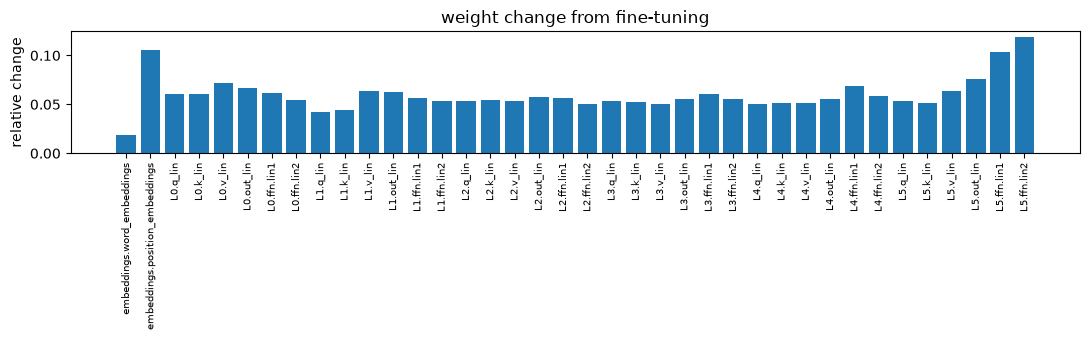

In [30]:
sd_base, sd_ft = base_model.state_dict(), ft_model.distilbert.state_dict()
change = pd.Series({k: float((sd_ft[k] - sd_base[k]).norm() / sd_base[k].norm())
                    for k in sd_base if sd_base[k].ndim == 2})

short = change.index.str.replace("transformer.layer.", "L").str.replace(".weight", "").str.replace("attention.", "")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(range(len(change)), change.values)
ax.set_xticks(range(len(change)), short, rotation=90, fontsize=7)
ax.set_ylabel("relative change"); ax.set_title("weight change from fine-tuning"); plt.tight_layout()
change.sort_values(ascending=False).head(5)

Every matrix moved only a few percent, and the **word embedding table
(layer 0) barely moved at all**. Small changes, but they compound layer
after layer, as we will see.

### 8.2 Gold annotations from MACCROBAT

In [31]:
maccrobat_dir = ner_helpers.download_maccrobat()
mac_sentences = ner_helpers.load_maccrobat_sentences(maccrobat_dir, keep_labels=set(COMPARE_LABELS))
print(len(mac_sentences), "sentences from", len({s.doc_id for s in mac_sentences}), "reports")

example = next(s for s in mac_sentences if len(s.spans) >= 4)
show_entities(example.text, [(sp.start, sp.end, sp.label) for sp in example.spans], f"gold — MACCROBAT {example.doc_id}")

4541 sentences from 200 reports


We now collect a **balanced** sample of words — `WORDS_PER_LABEL` per entity
type — and, for each word, its vector **at every layer** in **both** models.
As before, a word is represented by the vector of its first piece.

In [32]:
import random, collections

def hidden_states(model, input_ids):
    with torch.no_grad():
        return model(input_ids=input_ids, output_hidden_states=True).hidden_states

order = list(range(len(mac_sentences)))
random.Random(0).shuffle(order)

counts, records, vec_base, vec_ft = collections.Counter(), [], [], []
for i in order:
    s = mac_sentences[i]
    s_enc, words = ner_helpers.word_labels(tokenizer, s)
    wanted = [w for w in words if w["label"] in COMPARE_LABELS and counts[w["label"]] < WORDS_PER_LABEL]
    if not wanted:
        continue
    ids = torch.tensor([s_enc["input_ids"]])
    hb, hf = hidden_states(base_model, ids), hidden_states(ft_model.distilbert, ids)
    for w in wanted:
        counts[w["label"]] += 1
        records.append({"word": w["word"], "label": w["label"], "doc": s.doc_id})
        vec_base.append(torch.stack([h[0, w["first_token"]] for h in hb]).numpy())
        vec_ft.append(torch.stack([h[0, w["first_token"]] for h in hf]).numpy())
    if all(counts[l] >= WORDS_PER_LABEL for l in COMPARE_LABELS):
        break

words_df = pd.DataFrame(records)
X = {"base": np.stack(vec_base), "fine-tuned": np.stack(vec_ft)}   # (n_words, 7 layers, 768)
y = words_df["label"].to_numpy()
N_LAYERS = X["base"].shape[1]
print({k: v.shape for k, v in X.items()})
words_df.groupby("label").head(3).sort_values("label")

{'base': (904, 7, 768), 'fine-tuned': (904, 7, 768)}


,word,label,doc
10,heart,Biological_structure,28353588
4,site,Biological_structure,22665582
9,lungs,Biological_structure,28353588
7,CT,Diagnostic_procedure,28353588
14,analysis,Diagnostic_procedure,28595573
13,Genetic,Diagnostic_procedure,28595573
21,porphyria,Disease_disorder,23035161
18,leiomyoma,Disease_disorder,28353588
17,esophageal,Disease_disorder,28353588
71,HAART,Medication,28216610


### 8.3 Distance to the "entity type"

The base model has no classifier, so there is no ready-made vector for
*"Sign_symptom"*. We define one for both models in the same way: the
**centroid** (mean vector) of all words of that type. For every word we then
measure, by cosine distance:

* **own** — distance to the centroid of its own type
* **nearest other** — distance to the closest centroid of a different type

Raw BERT vectors all point in a similar direction (they are *anisotropic*),
so we first subtract the overall mean vector; otherwise every cosine is
close to 1 and nothing can be compared.

own            nearest_other            margin           
model   base fine-tuned          base fine-tuned   base fine-tuned
layer                                                             
0      0.874      0.872         0.924      0.925  0.049      0.053
1      0.847      0.834         0.902      0.910  0.056      0.076
2      0.838      0.815         0.874      0.891  0.036      0.076
3      0.804      0.737         0.863      0.900  0.060      0.163
4      0.768      0.588         0.862      0.909  0.094      0.321
5      0.735      0.467         0.848      0.901  0.113      0.434
6      0.701      0.431         0.833      0.941  0.132      0.511

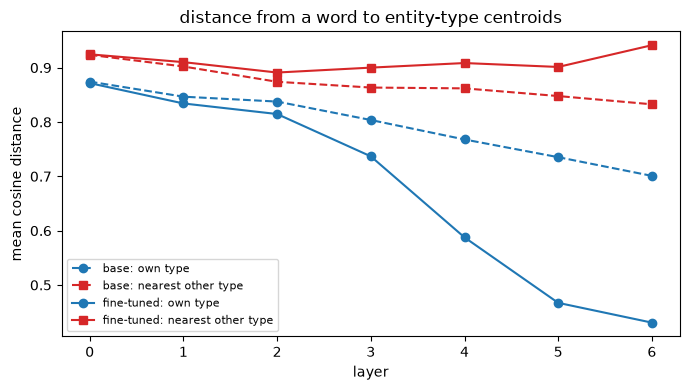

In [33]:
def centroid_distances(V, y):
    # cosine distance of each row of V to its own class centroid and to the nearest other one
    V = V - V.mean(0)
    V = V / np.linalg.norm(V, axis=1, keepdims=True)
    labels = sorted(set(y))
    C = np.stack([V[y == l].mean(0) for l in labels])
    C = C / np.linalg.norm(C, axis=1, keepdims=True)
    D = 1 - V @ C.T                                  # (n_words, n_types)
    own_idx = np.array([labels.index(l) for l in y])
    own = D[np.arange(len(y)), own_idx]
    D[np.arange(len(y)), own_idx] = np.inf
    return own, D.min(1)

rows = []
for name, V in X.items():
    for layer in range(N_LAYERS):
        own, other = centroid_distances(V[:, layer], y)
        rows.append({"model": name, "layer": layer, "own": own.mean(), "nearest_other": other.mean(),
                     "margin": (other - own).mean()})
dist = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
for name, style in [("base", "--"), ("fine-tuned", "-")]:
    d = dist[dist.model == name]
    ax.plot(d.layer, d.own, "o" + style, color="C0", label=f"{name}: own type")
    ax.plot(d.layer, d.nearest_other, "s" + style, color="C3", label=f"{name}: nearest other type")
ax.set_xlabel("layer"); ax.set_ylabel("mean cosine distance"); ax.legend(fontsize=8)
ax.set_title("distance from a word to entity-type centroids"); plt.tight_layout()
dist.pivot(index="layer", columns="model", values=["own", "nearest_other", "margin"]).round(3)

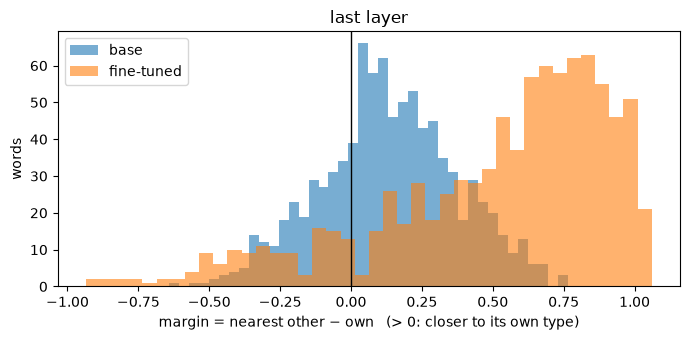

In [34]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name in X:
    own, other = centroid_distances(X[name][:, -1], y)
    ax.hist(other - own, bins=40, alpha=0.6, label=name)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("margin = nearest other − own   (> 0: closer to its own type)")
ax.set_ylabel("words"); ax.set_title("last layer"); ax.legend(); plt.tight_layout()

### 8.4 Seeing it: 2-D projections

PCA squeezes the 768 dimensions into the 2 directions of largest variance.
It is only a shadow of the real space, but the contrast is telling.

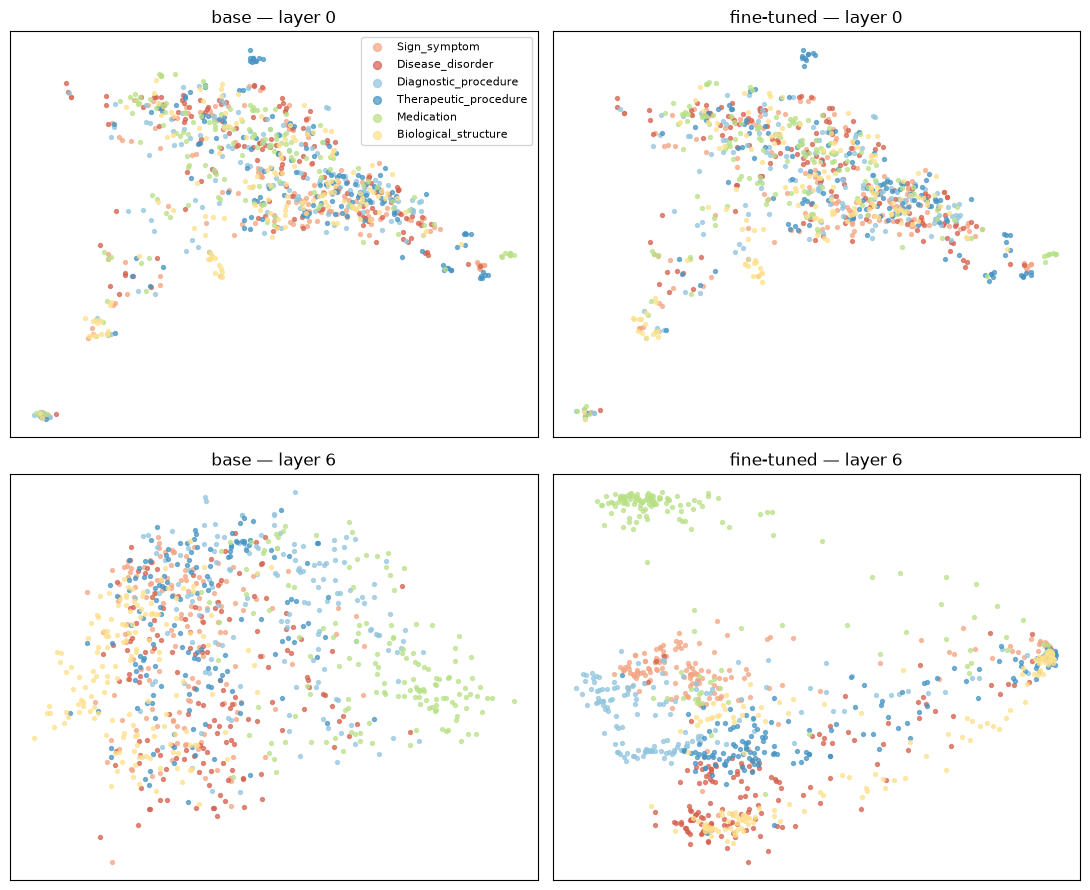

In [35]:
from sklearn.decomposition import PCA

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, layer in enumerate([0, N_LAYERS - 1]):
    for c, name in enumerate(X):
        P = PCA(2, random_state=0).fit_transform(X[name][:, layer] - X[name][:, layer].mean(0))
        ax = axes[r, c]
        for l in COMPARE_LABELS:
            m = y == l
            ax.scatter(P[m, 0], P[m, 1], s=8, alpha=0.7, color=COLORS[l], label=l)
        ax.set_title(f"{name} — layer {layer}"); ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].legend(fontsize=8, markerscale=2)
plt.tight_layout()

### 8.5 Three ways to quantify "the types are separated"

| Measure | Question it answers |
|---|---|
| **silhouette** (−1 … 1) | are words closer to their own type than to the next type, on average? |
| **nearest-centroid accuracy** | if we label each word with its closest centroid, how often are we right? |
| **linear probe accuracy** | can a *linear* classifier (logistic regression) trained on these frozen vectors recover the type? |

The last two use 5-fold cross-validation (fit on 4/5 of the words, test on
the remaining 1/5).

silhouette            nearest_centroid_acc            linear_probe_acc  \
model       base fine-tuned                 base fine-tuned             base   
layer                                                                          
0         -0.001     -0.000                0.427      0.445            0.419   
1          0.001      0.006                0.528      0.583            0.602   
2         -0.002      0.007                0.500      0.576            0.613   
3          0.004      0.035                0.542      0.752            0.673   
4          0.010      0.132                0.633      0.910            0.746   
5          0.015      0.237                0.660      0.904            0.773   
6          0.033      0.291                0.684      0.864            0.825   

                  
model fine-tuned  
layer             
0          0.428  
1          0.634  
2          0.713  
3          0.841  
4          0.940  
5          0.954  
6          0.935

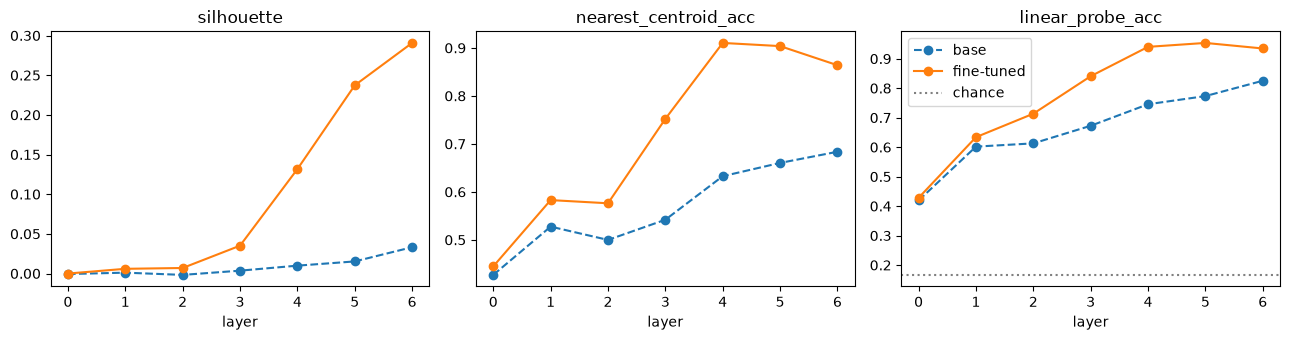

In [36]:
from sklearn.metrics import silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.neighbors import NearestCentroid
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = []
for name, V in X.items():
    for layer in range(N_LAYERS):
        Z = V[:, layer]
        nearest_centroid = make_pipeline(StandardScaler(with_std=False), Normalizer(), NearestCentroid())
        probe = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
        rows.append({
            "model": name, "layer": layer,
            "silhouette": silhouette_score(Z, y, metric="cosine"),
            "nearest_centroid_acc": cross_val_score(nearest_centroid, Z, y, cv=cv).mean(),
            "linear_probe_acc": cross_val_score(probe, Z, y, cv=cv).mean(),
        })
sep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, metric in zip(axes, ["silhouette", "nearest_centroid_acc", "linear_probe_acc"]):
    for name, style in [("base", "o--"), ("fine-tuned", "o-")]:
        d = sep[sep.model == name]
        ax.plot(d.layer, d[metric], style, label=name)
    ax.set_title(metric); ax.set_xlabel("layer")
axes[-1].axhline(1 / len(COMPARE_LABELS), color="gray", ls=":", label="chance")
axes[-1].legend(); plt.tight_layout()
sep.pivot(index="layer", columns="model", values=["silhouette", "nearest_centroid_acc", "linear_probe_acc"]).round(3)

**Reading the results**

* At **layer 0** the two models are practically identical — fine-tuning
  hardly touched the static embedding table.
* The curves split in the **upper layers**: in the fine-tuned model, words
  move much closer to their own type's centroid, and the types form
  tighter, better separated clusters.
* Yet the **linear probe** on the *base* model is already far above chance:
  the general-purpose model already *encodes* much of the information. What
  fine-tuning did was mainly to **reorganize** the space so that a single
  linear layer — the classifier — can read the types off directly.

### 🧩 Challenge 2 — geometry

1. Add `"O"` (words outside any entity) as a seventh class. What happens to
   the measures? Why is `O` a hard "class" to have a centroid for?
2. Represent each word by the **mean** of its pieces instead of the first
   piece. Do the conclusions change?
3. Repeat `plot_context_curves(base_model, BASE_MODEL)` from step 5 (it
   needs a tokenizer — they share one). Does fine-tuning change how strongly
   *culture* / *cold* depend on context?

In [37]:
# your code here

### 🧩 Challenge 3 — train your own classifier head

The linear probe *is* a NER classifier head. Train a logistic regression on
the **base** model's last-layer vectors (`X["base"][:, -1]`, `y`), then use it
to label the words of the MultiCaRe walkthrough `sentence`. How close do you
get to `d4data/biomedical-ner-all`? What is missing to make it a real NER
model (hint: think about `O` and about the B/I distinction)?

In [38]:
# your code here

## 9. A different architecture for the same task

The spaCy pipeline from step 1 already had a `ner` component. It uses no
Transformer: the `tok2vec` CNN from step 2 feeds a **transition-based**
parser that reads the sentence left to right and, at each token, chooses
one *move* from a small set (BILUO: **B**egin, **I**nside, **L**ast,
**U**nit-length, **O**utside). It was trained to mark biomedical mentions
without typing them.

In [39]:
spacy_ner = nlp.get_pipe("ner")
print("architecture:", nlp.config["components"]["ner"]["model"]["@architectures"])
print("moves       :", spacy_ner.move_names)

architecture: spacy.TransitionBasedParser.v2
moves       : ['B-ENTITY', 'I-ENTITY', 'L-ENTITY', 'U-ENTITY', 'O']


In [40]:
for s in [sentence] + sentences[1:4]:
    d = nlp(s)
    show_entities(s, [(e.start_char, e.end_char, e.label_) for e in d.ents], f"{SPACY_MODEL} (spaCy)")
    show_entities(s, [(x["start"], x["end"], x["entity_group"]) for x in ner_pipe(s)], FT_MODEL)

Because the decision is a sequence of moves rather than one softmax per
token, this model does not give us a per-token probability table like the
one in step 6 — one of the reasons we used the Transformer to open the box.

### 🧩 Challenge 4 — compare the two systems

Run both NER systems on 10 sentences of your choice from `cases`.

1. Where do the **span boundaries** disagree (ignore the labels — spaCy's
   are untyped)? Which system tends to produce longer spans?
2. Which mentions does each one miss? Relate what you find to the training
   data of each model.
3. *(Local machine with ≥ 4 GB free RAM)* Install scispaCy's typed model
   `en_ner_bc5cdr_md` (diseases and chemicals) and compare its types with
   d4data's.

In [41]:
# your code here